In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
import joblib

df = pd.read_csv("../data/raw/student_mental_health.csv")
df.head()


,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [42]:
#support vs stress
df["Support_Stress_Diff"] = df["Family_Support"] - df["Financial_Stress"]
#sleep vs stress
df["Stress_Sleep_Ratio"] = df["Financial_Stress"] / (df["Sleep_Hours"] + 0.01)


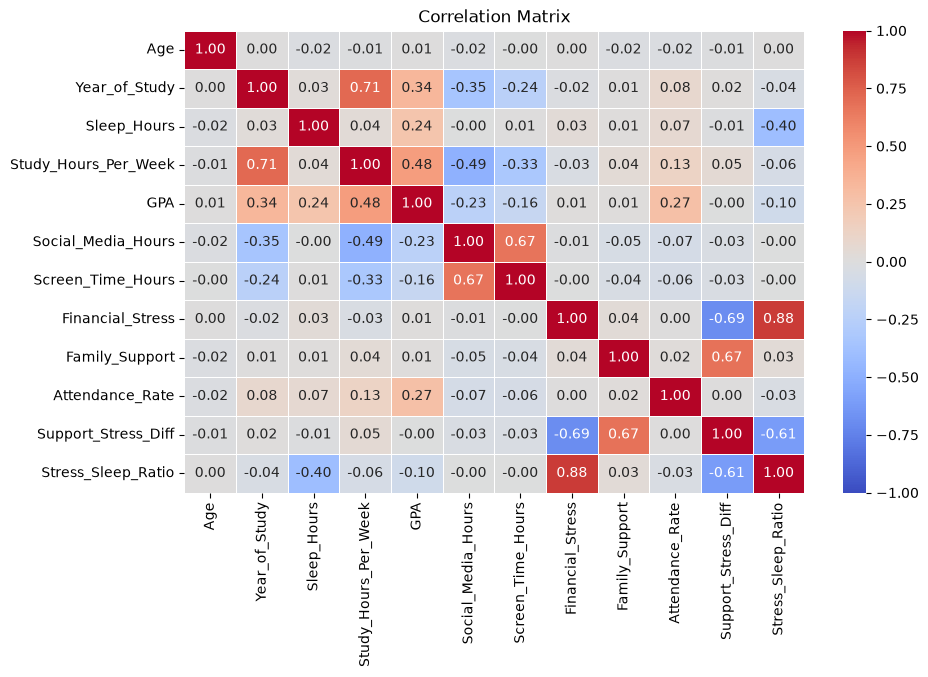

In [43]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df[numeric_cols].corr(method="spearman")

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()


In [44]:
target_mapping = {"Low": 0, "Medium": 1, "High": 2}
y = df["Mental_Health_Risk"].map(target_mapping)

drop_cols = ["Student_ID", "Mental_Health_Risk", "Age", "Gender", "Part_Time_Job"]
X = df.drop(columns=drop_cols)

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [45]:
ordinal_cols = ["Diet_Quality", "Physical_Activity"]
nominal_cols = ["Previous_Mental_Health_History"]
numerical_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numerical_cols),
    ("ord", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("enc", OrdinalEncoder(categories=[["Poor", "Average", "Good"], ["Low", "Moderate", "High"]]))]), ordinal_cols),
    ("nom", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("enc", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), nominal_cols)
])


In [46]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", GradientBoostingClassifier(random_state=42))
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingClassifier(random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(random_state=42, eval_metric="mlogloss"))
    ])
}


In [47]:
for name, model in models.items():
    model.fit(x_train, y_train)
    preds = model.predict(x_test)
    print(name)
    print(confusion_matrix(y_test, preds))
    print(classification_report(y_test, preds))


Logistic Regression
[[105  27   0]
 [ 19  87  26]
 [  1  21 114]]
              precision    recall  f1-score   support

           0       0.84      0.80      0.82       132
           1       0.64      0.66      0.65       132
           2       0.81      0.84      0.83       136

    accuracy                           0.77       400
   macro avg       0.77      0.76      0.76       400
weighted avg       0.77      0.77      0.77       400

Random Forest
[[101  27   4]
 [ 31  79  22]
 [  2  23 111]]
              precision    recall  f1-score   support

           0       0.75      0.77      0.76       132
           1       0.61      0.60      0.61       132
           2       0.81      0.82      0.81       136

    accuracy                           0.73       400
   macro avg       0.73      0.73      0.73       400
weighted avg       0.73      0.73      0.73       400

Gradient Boosting
[[106  25   1]
 [ 32  77  23]
 [  1  28 107]]
              precision    recall  f1-score   su

In [ ]:
param_grid = {
    "model__C": [0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
}

grid_search = GridSearchCV(
    models["Logistic Regression"],
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(x_train, y_train)

print("Best CV Accuracy:", round(grid_search.best_score_, 4))
print("Best Parameters:", grid_search.best_params_)


ValueError: Invalid parameter 'max_iter' for estimator Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Year_of_Study',
                                                   'Sleep_Hours',
                                                   'Study_Hours_Per_Week',
                                                   'GPA', 'Social_Media_Hours',
                                                   'Screen_Time_Hours',
                                                   'Financial_Stress',
                                                   'Family_Support',
             

In [49]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(x_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred))

joblib.dump(best_model, "../models/best_model_pipeline.joblib")


Confusion Matrix:
[[105  27   0]
 [ 19  87  26]
 [  1  21 114]]
Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.80      0.82       132
           1       0.64      0.66      0.65       132
           2       0.81      0.84      0.83       136

    accuracy                           0.77       400
   macro avg       0.77      0.76      0.76       400
weighted avg       0.77      0.77      0.77       400



['../models/best_model_pipeline.joblib']